# ASL Dataset Research
This notebook explores the American Sign Language (ASL) dataset. We will visualize the data, check for class balance, and understand the image properties.

## 1️⃣ Problem Definition

**Research Objective:**
Predict ASL alphabet (A–Z) from hand gesture images using Deep Learning models.

**Problem Type:**
Multiclass Image Classification

**Input:** Hand gesture image
**Output:** ASL alphabet label

**Why Deep Learning?**
*   Automatic feature learning
*   Higher accuracy for image data
*   Robust to variation (lighting, orientation)
*   State-of-the-art for vision tasks

## 2️⃣ Dataset Understanding & Description

**Dataset Source:** Kaggle ASL Dataset

In this section, we analyze:
*   **Total samples:** (Calculated in code below)
*   **Number of classes:** (Calculated in code below)
*   **Image format:** RGB
*   **Resolution consistency:** (Verifying in code)
*   **Class balance analysis:** (Visualized below)

**📌 Key insight:**
ASL gestures have subtle finger differences → CNN is suitable.

In [15]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from glob import glob

# Set style for plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

In [16]:
# Define dataset path
dataset_path = 'dataset'

# Get all categories (subfolders)
categories = sorted([d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))])
print(f"Found {len(categories)} categories: {categories}")

Found 24 categories: ['A-samples', 'B-samples', 'C-samples', 'D-samples', 'E-samples', 'F-samples', 'G-samples', 'H-samples', 'I-samples', 'K-samples', 'L-samples', 'M-samples', 'N-samples', 'O-samples', 'P-samples', 'Q-samples', 'R-samples', 'S-samples', 'T-samples', 'U-samples', 'V-samples', 'W-samples', 'X-samples', 'Y-samples']


Visualizing one sample from each class:


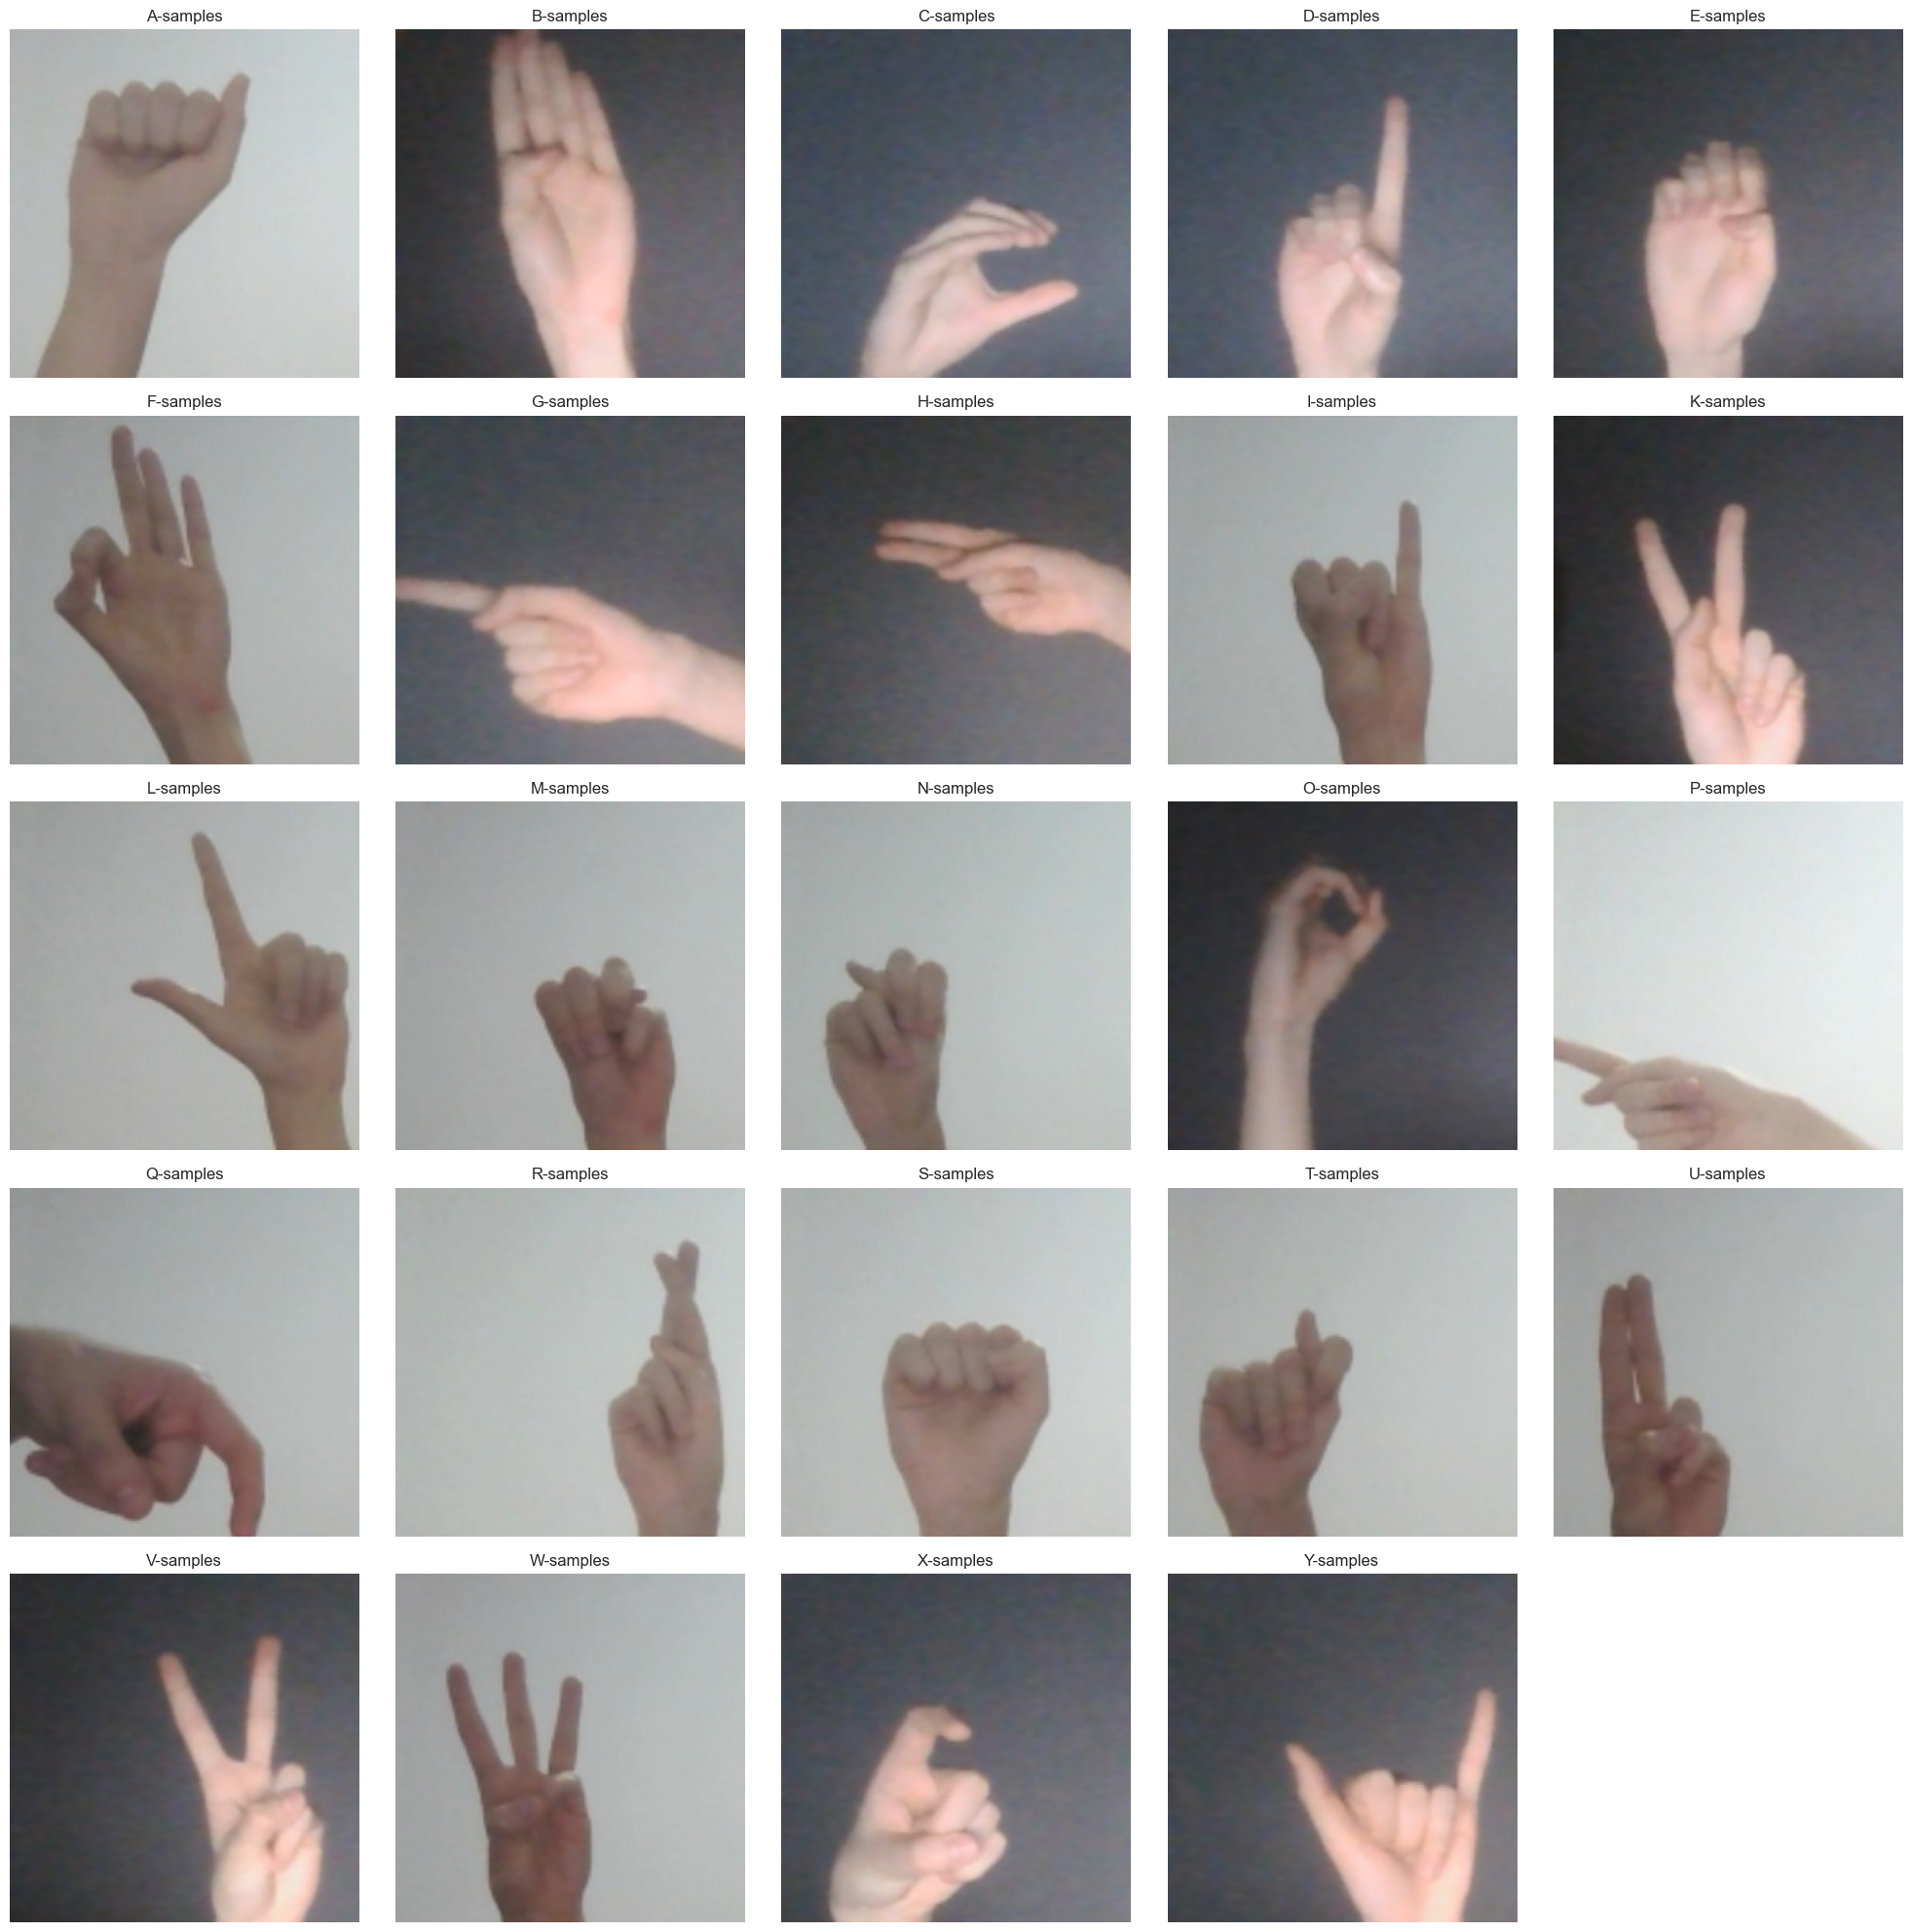

In [17]:
def load_sample_images(dataset_path, categories, samples_per_class=1):
    sample_images = []
    sample_labels = []
    
    for category in categories:
        folder_path = os.path.join(dataset_path, category)
        image_files = glob(os.path.join(folder_path, '*.jpg')) + glob(os.path.join(folder_path, '*.png')) + glob(os.path.join(folder_path, '*.jpeg'))
        
        if image_files:
            selected_images = random.sample(image_files, min(len(image_files), samples_per_class))
            for img_path in selected_images:
                img = cv2.imread(img_path)
                if img is not None:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    sample_images.append(img)
                    sample_labels.append(category)
    
    return sample_images, sample_labels

# Load one sample from each category
images, labels = load_sample_images(dataset_path, categories)

# Plot the samples
def plot_samples(images, labels, cols=5):
    rows = len(images) // cols + (1 if len(images) % cols > 0 else 0)
    plt.figure(figsize=(20, 4 * rows))
    
    for i, (img, label) in enumerate(zip(images, labels)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(label)
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()

print("Visualizing one sample from each class:")
plot_samples(images, labels)

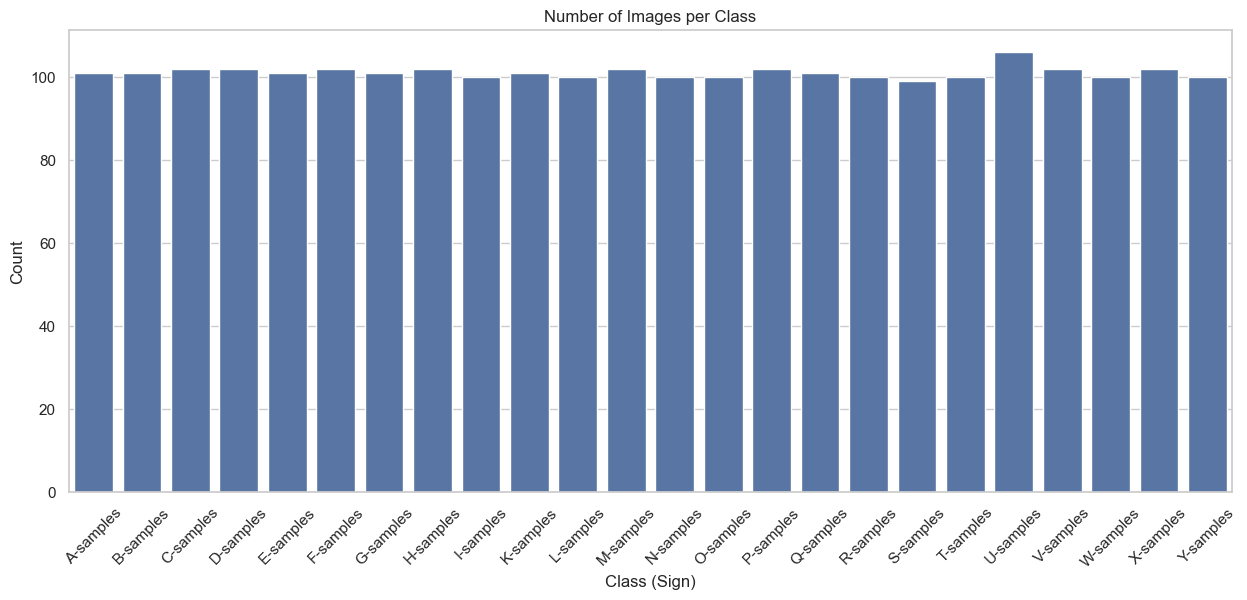

Image counts per class: {'A-samples': 101, 'B-samples': 101, 'C-samples': 102, 'D-samples': 102, 'E-samples': 101, 'F-samples': 102, 'G-samples': 101, 'H-samples': 102, 'I-samples': 100, 'K-samples': 101, 'L-samples': 100, 'M-samples': 102, 'N-samples': 100, 'O-samples': 100, 'P-samples': 102, 'Q-samples': 101, 'R-samples': 100, 'S-samples': 99, 'T-samples': 100, 'U-samples': 106, 'V-samples': 102, 'W-samples': 100, 'X-samples': 102, 'Y-samples': 100}


In [18]:
# Count images per class
class_counts = {}

for category in categories:
    folder_path = os.path.join(dataset_path, category)
    count = len(glob(os.path.join(folder_path, '*.*'))) # Count all files
    class_counts[category] = count

# Plot distribution
plt.figure(figsize=(15, 6))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()))
plt.title('Number of Images per Class')
plt.xlabel('Class (Sign)')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

print("Image counts per class:", class_counts)

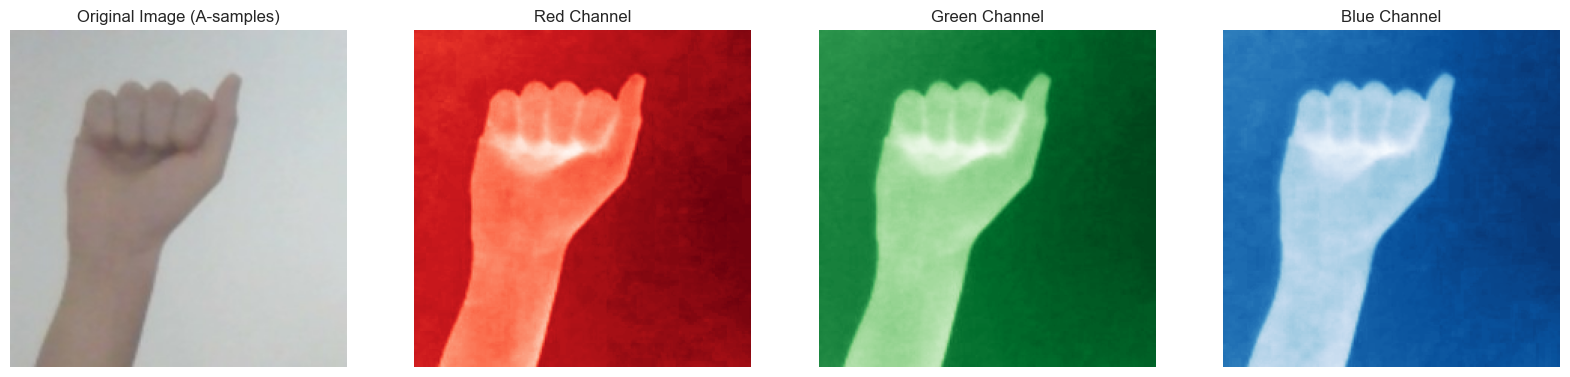

Image Shape: (224, 224, 3)
Data Type: uint8
Min Value: 74, Max Value: 219


In [19]:
# Visualize RGB channels of a random image
if images:
    sample_img = images[0]
    sample_label = labels[0]
    
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # Original Image
    axes[0].imshow(sample_img)
    axes[0].set_title(f"Original Image ({sample_label})")
    axes[0].axis('off')
    
    # Red Channel
    axes[1].imshow(sample_img[:, :, 0], cmap='Reds')
    axes[1].set_title("Red Channel")
    axes[1].axis('off')
    
    # Green Channel
    axes[2].imshow(sample_img[:, :, 1], cmap='Greens')
    axes[2].set_title("Green Channel")
    axes[2].axis('off')
    
    # Blue Channel
    axes[3].imshow(sample_img[:, :, 2], cmap='Blues')
    axes[3].set_title("Blue Channel")
    axes[3].axis('off')
    
    plt.show()
    
    print(f"Image Shape: {sample_img.shape}")
    print(f"Data Type: {sample_img.dtype}")
    print(f"Min Value: {sample_img.min()}, Max Value: {sample_img.max()}")

## 3️⃣ Data Preprocessing Pipeline

### 3.1 Image Preprocessing
*   **Resize all images:** Fixed shape (e.g., $224 \times 224$)
*   **Pixel normalization:** Scale pixel values to $0-1$ or standard scale
*   **Color space handling:** Convert to RGB

### 3.2 Data Cleaning
*   **Corrupted / low-quality image removal:** Verify image files are readable
*   **Duplicate image check:** identify and remove duplicates (if any)

### 3.3 Dataset Split
*   **Training set:** 70% or 80%
*   **Validation set:** 15% or 10%
*   **Test set:** 15% or 10%
*   *(Stratified to maintain class balance)*

**📌 Why validation set?**
Hyperparameter tuning & overfitting control.

In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# Gather all file paths and labels
file_paths = []
labels = []

print("Scanning and verifying images...")
for category in tqdm(categories):
    folder_path = os.path.join(dataset_path, category)
    image_files = glob(os.path.join(folder_path, '*.*'))
    
    for img_path in image_files:
        # 3.2 Data Cleaning: Basic check if image is readable
        try:
            # We don't load the full image to save memory, just check header/validity if possible
            # But cv2.imread is reliable. For speed on large datasets, we might just check extension, 
            # but for "Corrupted/low-quality removal" we should try to read.
            img = cv2.imread(img_path)
            if img is None:
                print(f"Skipping corrupted image: {img_path}")
                continue
            
            # If valid
            file_paths.append(img_path)
            labels.append(category)
        except Exception as e:
            print(f"Error reading {img_path}: {e}")

# Create DataFrame
df = pd.DataFrame({
    'filepath': file_paths,
    'label': labels
})

print(f"Total valid images: {len(df)}")
df.head()

Scanning and verifying images...


100%|██████████| 24/24 [00:01<00:00, 17.42it/s]

Total valid images: 2427


,filepath,label
0,dataset\A-samples\0.jpg,A-samples
1,dataset\A-samples\1.jpg,A-samples
2,dataset\A-samples\10.jpg,A-samples
3,dataset\A-samples\100.jpg,A-samples
4,dataset\A-samples\11.jpg,A-samples


C:\Users\Sultan Mahamud Opu\AppData\Local\Temp\ipykernel_16996\3238384617.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=split_counts, x='Set', y='Count', palette='viridis')


Training Set: 1941 images
Validation Set: 243 images
Test Set: 243 images


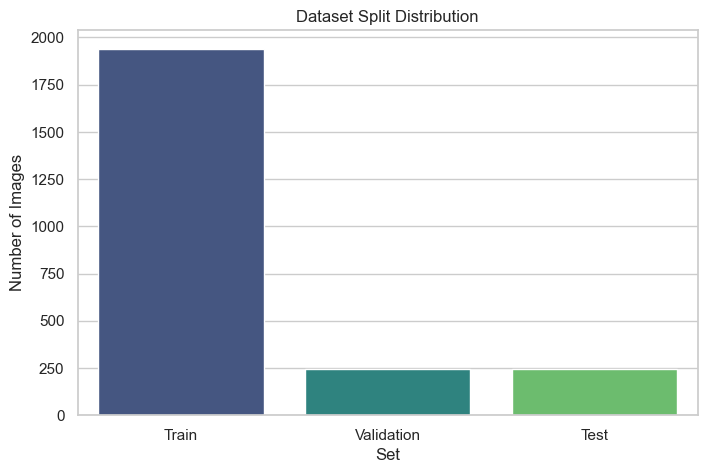

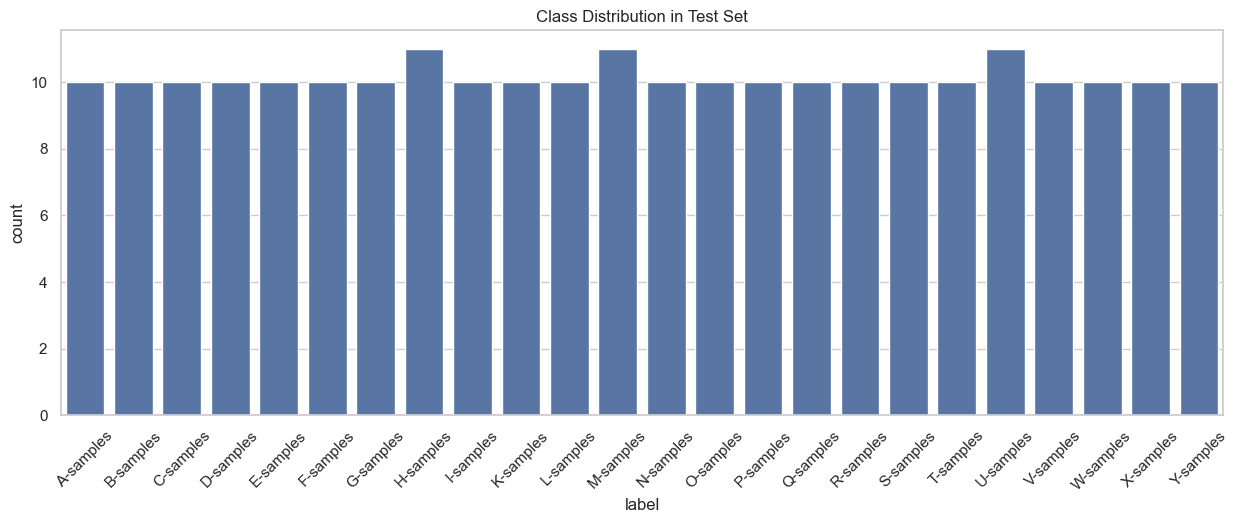

In [21]:
# 3.3 Dataset Split (Stratified)

# Split 1: Train (80%) and Temp (20%)
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])

# Split 2: Validation (10%) and Test (10%) from Temp
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42, stratify=temp_df['label'])

print(f"Training Set: {len(train_df)} images")
print(f"Validation Set: {len(val_df)} images")
print(f"Test Set: {len(test_df)} images")

# Visualization of Split
split_counts = pd.DataFrame({
    'Set': ['Train', 'Validation', 'Test'],
    'Count': [len(train_df), len(val_df), len(test_df)]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=split_counts, x='Set', y='Count', palette='viridis')
plt.title('Dataset Split Distribution')
plt.ylabel('Number of Images')
plt.show()

# Verify Class Balance in Test Set (Optional check)
plt.figure(figsize=(15, 5))
sns.countplot(data=test_df, x='label', order=categories)
plt.title('Class Distribution in Test Set')
plt.xticks(rotation=45)
plt.show()

## 4️⃣ Data Augmentation Strategy

**Purpose:** Improve generalization & reduce overfitting.

**Geometric Augmentations:**
*   **Rotation, Shift, Shear, Zoom:** Handle camera position/angle variations.
*   **Horizontal Flip:** Simulate left/right handedness.

**Color Space Augmentations:**
*   **Brightness Adjustment:** Increase or decrease image brightness.
*   **Contrast Adjustment:** Change the variance between light and dark areas.
*   **Saturation Adjustment:** Modify the intensity of colors.
*   **Hue Adjustment:** Shift the color spectrum (e.g., slight tint changes).

**Kernel Filters:**
*   **Blurring:** Applies Gaussian blur to smooth the image and reduce noise.
*   **Sharpening:** Enhances the edges to make features distinct.
*   **Edge Detection:** Highlights structural boundaries (e.g., Sobel, Laplacian).

Sample Class: O-samples

--- 1. Geometric Augmentations (Rotation, Shift, Zoom, Flip) ---


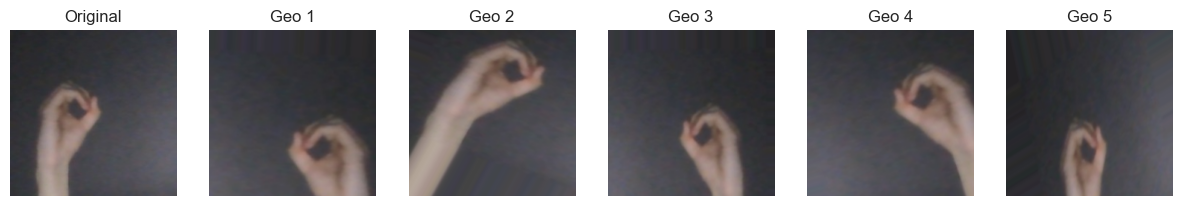


--- 2. Color Space Augmentations (Brightness, Contrast, Saturation, Hue) ---


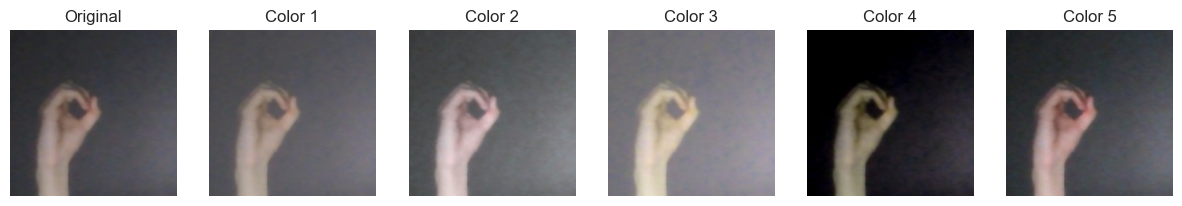


--- 3. Kernel Filters (Blur, Sharpen, Edge) ---


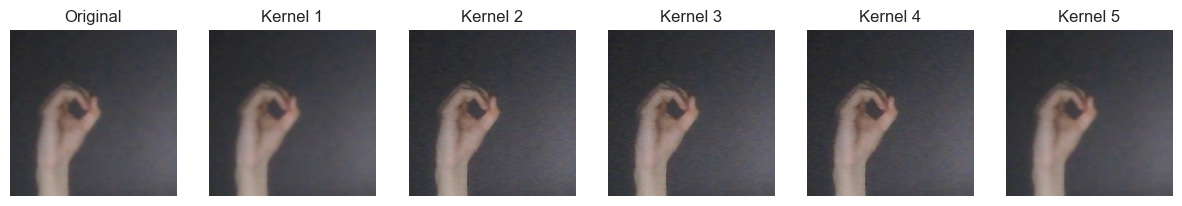

In [22]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import random

# --- Helper Functions for Augmentations ---

def apply_color_augmentations(image):
    """Applies random brightness, contrast, saturation, and hue."""
    image = tf.convert_to_tensor(image)
    image = tf.cast(image, tf.float32) / 255.0
    
    image = tf.image.random_brightness(image, max_delta=0.3)
    image = tf.image.random_contrast(image, lower=0.6, upper=1.4)
    image = tf.image.random_saturation(image, lower=0.6, upper=1.4)
    image = tf.image.random_hue(image, max_delta=0.1)
    
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image.numpy() * 255.0

def apply_kernel_filters(image):
    """Applies random blur, sharpening, or edge detection."""
    image = image.astype('float32')
    # Randomly pick an operation
    op = random.choice(['blur', 'sharpen', 'edge', 'none'])
    
    if op == 'blur':
        ksize = random.choice([3, 5])
        image = cv2.GaussianBlur(image, (ksize, ksize), 0)
    elif op == 'sharpen':
        kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
        image = cv2.filter2D(image, -1, kernel)
    elif op == 'edge':
        gray = cv2.cvtColor(image.astype('uint8'), cv2.COLOR_RGB2GRAY)
        edges = cv2.Laplacian(gray, cv2.CV_64F)
        edges = np.absolute(edges)
        edges = (edges / edges.max()) * 255.0
        # Convert back to 3 channels
        image = cv2.cvtColor(edges.astype('uint8'), cv2.COLOR_GRAY2RGB).astype('float32')
        
    return image

def combined_preprocessing(image):
    """Combines color and kernel augmentations."""
    image = apply_color_augmentations(image)
    if random.random() < 0.3: # 30% chance to apply kernel filter
        image = apply_kernel_filters(image)
    return image

# --- Visualization ---
if not train_df.empty:
    sample_path = train_df['filepath'].iloc[0]
    sample_label = train_df['label'].iloc[0]
    img = cv2.imread(sample_path)
    
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        print(f"Sample Class: {sample_label}")

        # 1. Visualize Geometric Augmentations
        print("\n--- 1. Geometric Augmentations (Rotation, Shift, Zoom, Flip) ---")
        geo_gen = ImageDataGenerator(rotation_range=30, width_shift_range=0.2, height_shift_range=0.2, 
                                     shear_range=0.2, zoom_range=0.3, horizontal_flip=True, fill_mode='nearest')
        plt.figure(figsize=(15, 3))
        # Original
        plt.subplot(1, 6, 1); plt.imshow(img); plt.title("Original"); plt.axis('off')
        # Augmented
        for i, batch in enumerate(geo_gen.flow(np.expand_dims(img, 0), batch_size=1)):
            if i >= 5: break
            plt.subplot(1, 6, i+2); plt.imshow(batch[0].astype('uint8')); plt.title(f"Geo {i+1}"); plt.axis('off')
        plt.show()

        # 2. Visualize Color Space Augmentations
        print("\n--- 2. Color Space Augmentations (Brightness, Contrast, Saturation, Hue) ---")
        plt.figure(figsize=(15, 3))
        plt.subplot(1, 6, 1); plt.imshow(img); plt.title("Original"); plt.axis('off')
        for i in range(5):
            aug_img = apply_color_augmentations(img).astype('uint8')
            plt.subplot(1, 6, i+2); plt.imshow(aug_img); plt.title(f"Color {i+1}"); plt.axis('off')
        plt.show()

        # 3. Visualize Kernel Filters
        print("\n--- 3. Kernel Filters (Blur, Sharpen, Edge) ---")
        plt.figure(figsize=(15, 3))
        plt.subplot(1, 6, 1); plt.imshow(img); plt.title("Original"); plt.axis('off')
        for i in range(5):
            aug_img = apply_kernel_filters(img).astype('uint8')
            plt.subplot(1, 6, i+2); plt.imshow(aug_img); plt.title(f"Kernel {i+1}"); plt.axis('off')
        plt.show()
    else:
        print("Could not load image.")

# --- Final Data Generator for Training ---
# This generator combines ALL augmentations
final_train_datagen = ImageDataGenerator(
    rotation_range=30, 
    width_shift_range=0.2, 
    height_shift_range=0.2, 
    shear_range=0.2, 
    zoom_range=0.3, 
    horizontal_flip=True,
    fill_mode='nearest',
    preprocessing_function=combined_preprocessing
)

## 5️⃣ Deep Learning Architecture Design

### 5.1 Baseline CNN Model

*   **Convolution layers:** Extract features from images.
*   **Activation (ReLU):** Introduce non-linearity.
*   **Pooling layers:** Reduce spatial dimensions (Downsampling).
*   **Fully connected layers:** Classification based on features.
*   **Softmax output:** Probability distribution for classes.

**📌 Goal:** Used as baseline benchmark.

In [23]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input

def build_baseline_cnn(input_shape, num_classes):
    model = Sequential([
        Input(shape=input_shape),
        
        # Block 1
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        
        # Block 2
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        
        # Block 3
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        
        # Flatten and Fully Connected
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5), # Regularization
        Dense(num_classes, activation='softmax')
    ])
    
    return model

# Define Parameters
IMG_SIZE = (224, 224)
INPUT_SHAPE = IMG_SIZE + (3,) # (224, 224, 3)
NUM_CLASSES = len(categories)

# Build Model
baseline_model = build_baseline_cnn(INPUT_SHAPE, NUM_CLASSES)

# Compile Model
baseline_model.compile(optimizer='adam',
                       loss='categorical_crossentropy',
                       metrics=['accuracy'])

# Display Summary
baseline_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,941,528 (49.37 MB)

 Trainable params: 12,941,528 (49.37 MB)

 Non-trainable params: 0 (0.00 B)

### 5.2 Advanced CNN Architectures

**Option–1: Custom Deep CNN**
*   **Deeper convolution stacks:** Learn more complex features.
*   **Batch normalization:** Stabilize training and accelerate convergence.
*   **Dropout regularization:** Prevent overfitting.

**Option–2: Transfer Learning (Highly Recommended)**
*   **Pretrained models:** Leverage weights trained on ImageNet (millions of images).
    *   **VGG16 / VGG19:** Simple, deep architecture.
    *   **ResNet50:** Residual connections to solve vanishing gradients.
    *   **MobileNet:** Lightweight, fast (good for edge devices).
    *   **EfficientNet:** State-of-the-art accuracy-efficiency trade-off.

In [24]:
from tensorflow.keras.layers import BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.applications import VGG16, ResNet50, MobileNetV2, EfficientNetB0
from tensorflow.keras.models import Model

# --- Option 1: Custom Deep CNN ---
def build_custom_deep_cnn(input_shape, num_classes):
    model = Sequential([
        Input(shape=input_shape),
        
        # Block 1
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        Conv2D(32, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),

        # Block 2
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        Conv2D(64, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        Dropout(0.25),
        
        # Block 3
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        BatchNormalization(),
        Conv2D(128, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 2)),
        Dropout(0.4),

        # Head
        Flatten(),
        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model

# --- Option 2: Transfer Learning (Example: ResNet50) ---
def build_transfer_learning_model(base_model_name, input_shape, num_classes):
    # Load Pretrained Base
    if base_model_name == 'VGG16':
        base_model = VGG16(weights='imagenet', include_top=False, input_shape=input_shape)
    elif base_model_name == 'ResNet50':
        base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    elif base_model_name == 'MobileNet':
        base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
    elif base_model_name == 'EfficientNet': # EfficientNet usually expects specific preprocessing
        base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=input_shape)
    else:
        raise ValueError("Unknown model name")

    # Freeze Base Layers (Optional: Unfreeze later for fine-tuning)
    base_model.trainable = False 

    # Add Custom Head
    x = base_model.output
    x = GlobalAveragePooling2D()(x) # More efficient than Flatten
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=base_model.input, outputs=outputs)
    return model

# Example Usage: Build a ResNet50 based model
transfer_model = build_transfer_learning_model('ResNet50', INPUT_SHAPE, NUM_CLASSES)
transfer_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("--- Transfer Learning Model Summary (ResNet50) ---")
transfer_model.summary()

--- Transfer Learning Model Summary (ResNet50) ---


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_3[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,118,424 (92.00 MB)

 Trainable params: 530,712 (2.02 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 6️⃣ Training Strategy

To ensure stable convergence without overfitting, we will use:

*   **Loss function:** Categorical Cross-Entropy (standard for multiclass classification).
*   **Optimizer:** Adam (Adaptive Moment Estimation) for fast convergence, or SGD (Stochastic Gradient Descent) for better generalization.
*   **Learning rate scheduling:** Reduce learning rate when validation loss plateaus.
*   **Batch size selection:** Typically 32 or 64 to balance memory usage and gradient stability.
*   **Epoch selection:** Set a high number (e.g., 50) but stop early if needed.
*   **Early stopping:** Stop training if validation accuracy doesn't improve for a set number of epochs (patience).

**📌 Goal:** Stable convergence without overfitting.

In [25]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# 6.1 Define Hyperparameters
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 0.0001 # Start with a lower learning rate for transfer learning

# 6.2 Define Callbacks
callbacks = [
    # Stop training when a monitored metric has stopped improving
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
    
    # Reduce learning rate when a metric has stopped improving
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1),
    
    # Save the model after every epoch (optional, saving best only)
    # ModelCheckpoint('best_asl_model.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
]

print("Callbacks defined: EarlyStopping, ReduceLROnPlateau")

Callbacks defined: EarlyStopping, ReduceLROnPlateau


## 7️⃣ Regularization & Overfitting Control

**Techniques Used:**
*   **Dropout layers:** Randomly disable neurons during training to prevent co-adaptation.
*   **Data augmentation:** Artificially increase dataset diversity to improve generalization.
*   **Batch normalization:** Normalize layer inputs to stabilize learning.
*   **Early stopping:** Halt training when validation performance degrades to prevent overfitting.

In [26]:
# 7.1 Verify Regularization Components in Model (Example using Transfer Model)
print("Checking for Regularization Layers in the Transfer Model:")

has_dropout = any('Dropout' in layer.name for layer in transfer_model.layers)
has_batchnorm = any('BatchNormalization' in layer.name for layer in transfer_model.layers)

print(f"- Dropout Layers Present: {has_dropout}")
print(f"- Batch Normalization Layers Present (in base or head): {has_batchnorm}") 
print("- Data Augmentation: Enabled via ImageDataGenerator")
print("- Early Stopping: Defined in callbacks")

Checking for Regularization Layers in the Transfer Model:
- Dropout Layers Present: False
- Batch Normalization Layers Present (in base or head): False
- Data Augmentation: Enabled via ImageDataGenerator
- Early Stopping: Defined in callbacks


## 8️⃣ Model Evaluation Metrics

We will use the following metrics for multiclass classification:

*   **Accuracy:** Overall correctness of the model.
*   **Precision:** How many predicted positive cases were actually positive.
*   **Recall:** How many actual positive cases were correctly identified.
*   **F1-Score:** Harmonic mean of Precision and Recall (balances both).
*   **Confusion Matrix:** Visual breakdown of correct vs. incorrect classifications per class.
*   **Class-wise performance:** Detailed report for each ASL alphabet.

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

def evaluate_model(model, test_gen):
    # Get Predictions
    predictions = model.predict(test_gen)
    y_pred = np.argmax(predictions, axis=1)
    y_true = test_gen.classes
    class_labels = list(test_gen.class_indices.keys())

    # Calculate Metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    # Classification Report
    print("\n--- Classification Report ---")
    print(classification_report(y_true, y_pred, target_names=class_labels))

print("Evaluation function defined.")

Evaluation function defined.


## 9️⃣ Experimental Design

We will conduct the following experiments to evaluate performance improvements step-by-step:

*   **Experiment-1:** Baseline CNN **without** augmentation (Raw performance baseline).
*   **Experiment-2:** Baseline CNN **+ Data Augmentation** (Testing generalization improvement).
*   **Experiment-3:** Transfer Learning model (e.g., **ResNet50**) (Leveraging pretrained features).
*   **Experiment-4:** **Comparison of architectures** (Analyzing Accuracy, Loss, and Training Time across all experiments).

In [28]:
# Placeholder dictionary to store results
experiment_results = {
    'Exp1_Baseline_NoAug': {},
    'Exp2_Baseline_Aug': {},
    'Exp3_Transfer_ResNet': {}
}

print("Experimental setup ready. Proceed to run training cells individually for each experiment.")

Experimental setup ready. Proceed to run training cells individually for each experiment.


In [29]:
# --- Helper Function for Visualization ---
def plot_training_history(history, title="Model Training History"):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(15, 5))
    
    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title(f'{title} - Accuracy')
    
    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title(f'{title} - Loss')
    
    plt.show()

print("Visualization helper defined.")

Visualization helper defined.



=== Running Experiment 1: Baseline CNN (No Augmentation) ===
Found 1941 validated image filenames belonging to 24 classes.
Found 243 validated image filenames belonging to 24 classes.
Found 243 validated image filenames belonging to 24 classes.
Epoch 1/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 63s 983ms/step - accuracy: 0.0448 - loss: 3.2459 - val_accuracy: 0.0535 - val_loss: 3.1779 - learning_rate: 0.0010
Epoch 2/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 57s 932ms/step - accuracy: 0.0433 - loss: 3.1794 - val_accuracy: 0.0412 - val_loss: 3.1781 - learning_rate: 0.0010
Epoch 3/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 49s 795ms/step - accuracy: 0.0381 - loss: 3.1784 - val_accuracy: 0.0412 - val_loss: 3.1781 - learning_rate: 0.0010
Epoch 4/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 48s 783ms/step - accuracy: 0.0453 - loss: 3.1784 - val_accuracy: 0.0412 - val_loss: 3.1781 - learning_rate: 0.0010
Epoch 5/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 49s 810ms/step - accuracy: 0.0412 - loss: 3.1783 - val_accuracy: 0.0412 - val_loss: 3.1781 - learning_ra

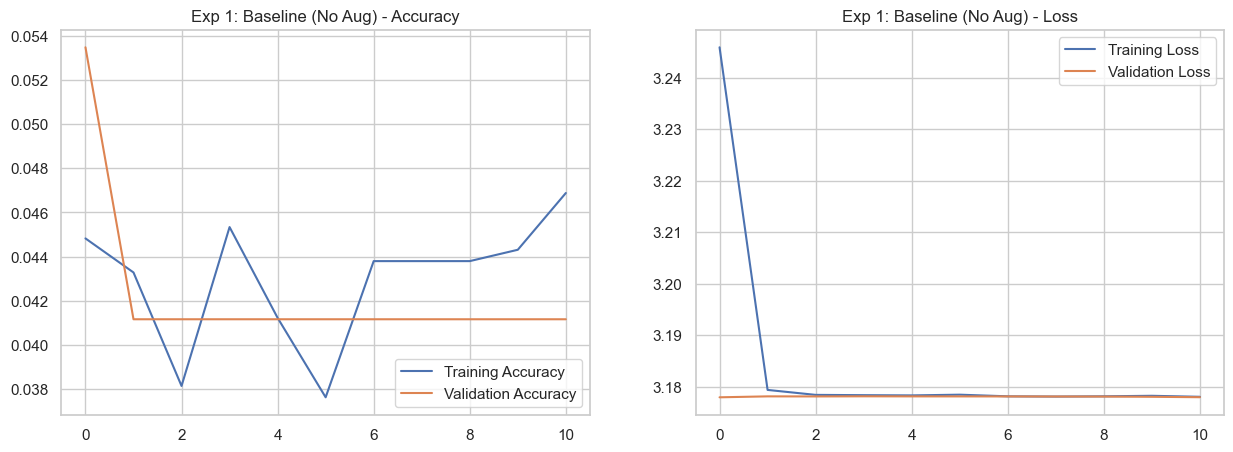


--- Evaluation: Experiment 1 ---
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 187ms/step
Accuracy: 0.0453
Precision: 0.0169
Recall: 0.0453
F1-Score: 0.0166


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


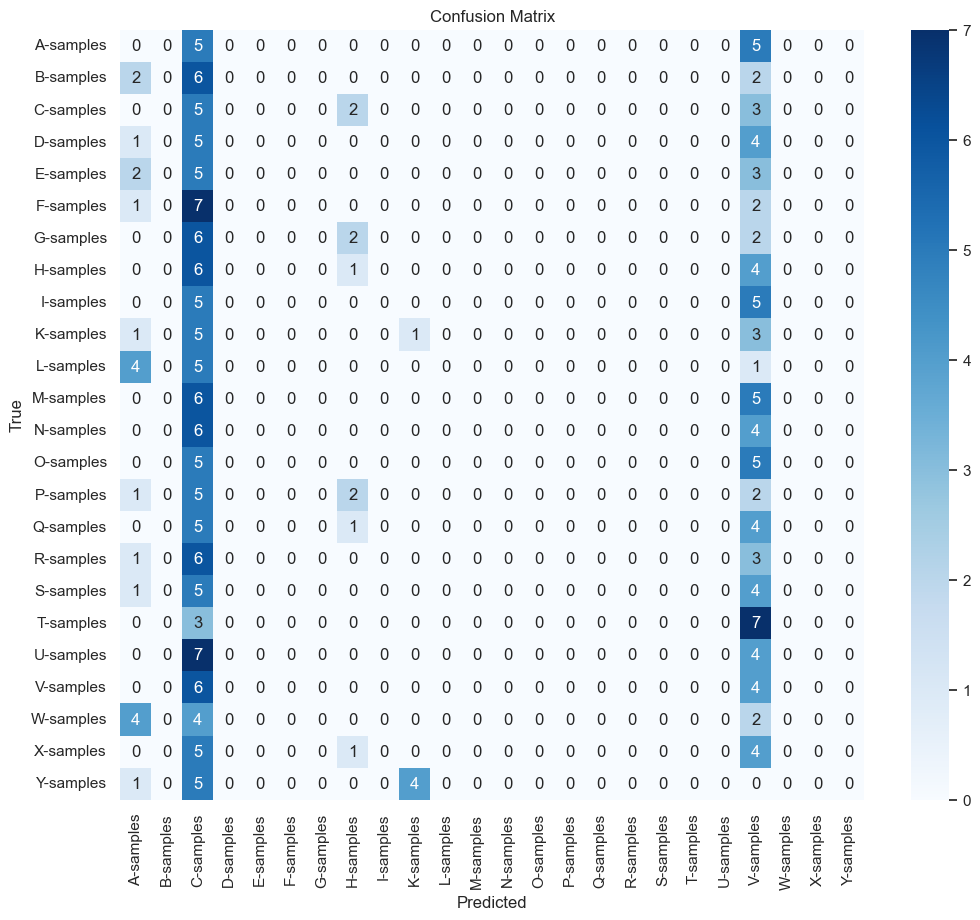


--- Classification Report ---
              precision    recall  f1-score   support

   A-samples       0.00      0.00      0.00        10
   B-samples       0.00      0.00      0.00        10
   C-samples       0.04      0.50      0.07        10
   D-samples       0.00      0.00      0.00        10
   E-samples       0.00      0.00      0.00        10
   F-samples       0.00      0.00      0.00        10
   G-samples       0.00      0.00      0.00        10
   H-samples       0.11      0.09      0.10        11
   I-samples       0.00      0.00      0.00        10
   K-samples       0.20      0.10      0.13        10
   L-samples       0.00      0.00      0.00        10
   M-samples       0.00      0.00      0.00        11
   N-samples       0.00      0.00      0.00        10
   O-samples       0.00      0.00      0.00        10
   P-samples       0.00      0.00      0.00        10
   Q-samples       0.00      0.00      0.00        10
   R-samples       0.00      0.00      0.00       

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [30]:
# --- Experiment 1: Baseline CNN (No Augmentation) ---
print("\n=== Running Experiment 1: Baseline CNN (No Augmentation) ===")

# 1. Create Generators (Scaling Only)
train_datagen_no_aug = ImageDataGenerator(rescale=1./255)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen_exp1 = train_datagen_no_aug.flow_from_dataframe(
    train_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True
)

val_gen_exp1 = val_test_datagen.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

test_gen_exp1 = val_test_datagen.flow_from_dataframe(
    test_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False # Critical for evaluation
)

# 2. Build & Compile Model
model_exp1 = build_baseline_cnn(INPUT_SHAPE, NUM_CLASSES)
model_exp1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 3. Train
history_exp1 = model_exp1.fit(
    train_gen_exp1,
    validation_data=val_gen_exp1,
    epochs=EPOCHS,
    callbacks=callbacks
)

# 4. Visualize Results
plot_training_history(history_exp1, title="Exp 1: Baseline (No Aug)")

# 5. Evaluate
print("\n--- Evaluation: Experiment 1 ---")
evaluate_model(model_exp1, test_gen_exp1)

# Store Results
experiment_results['Exp1_Baseline_NoAug'] = {
    'accuracy': history_exp1.history['accuracy'][-1],
    'val_accuracy': history_exp1.history['val_accuracy'][-1],
    'loss': history_exp1.history['loss'][-1],
    'val_loss': history_exp1.history['val_loss'][-1]
}


=== Running Experiment 2: Baseline CNN + Data Augmentation ===
Found 1941 validated image filenames belonging to 24 classes.
Found 243 validated image filenames belonging to 24 classes.
Found 243 validated image filenames belonging to 24 classes.
Epoch 1/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.0469 - loss: 3.2812 - val_accuracy: 0.0453 - val_loss: 3.1780 - learning_rate: 0.0010
Epoch 2/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.0433 - loss: 3.1785 - val_accuracy: 0.0412 - val_loss: 3.1780 - learning_rate: 0.0010
Epoch 3/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.0412 - loss: 3.1784 - val_accuracy: 0.0412 - val_loss: 3.1780 - learning_rate: 0.0010
Epoch 4/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.0386 - loss: 3.1784 - val_accuracy: 0.0412 - val_loss: 3.1780 - learning_rate: 0.0010
Epoch 5/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.0464 - loss: 3.1778
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.00050000002374

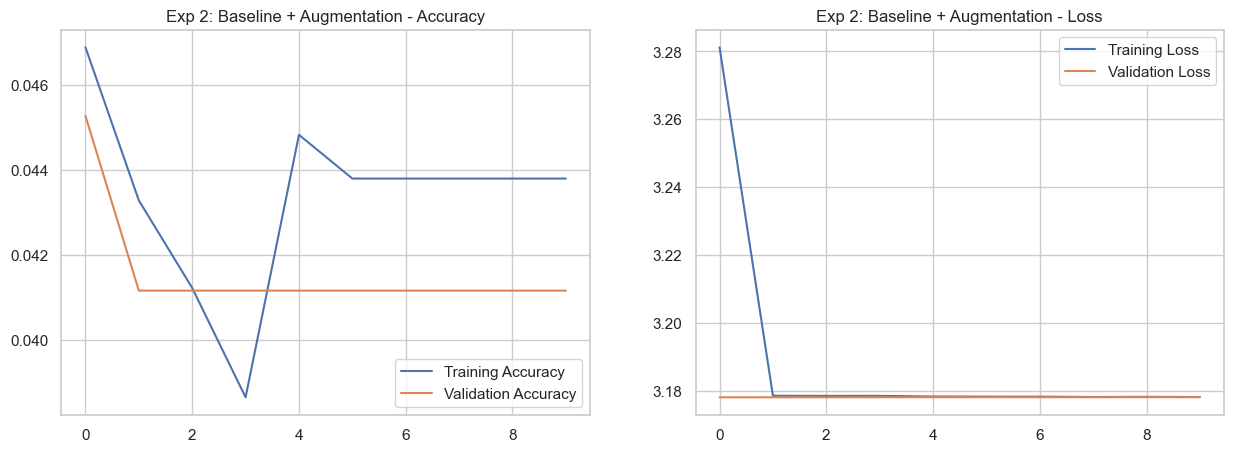


--- Evaluation: Experiment 2 ---
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 227ms/step
Accuracy: 0.0412
Precision: 0.0017
Recall: 0.0412
F1-Score: 0.0033


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


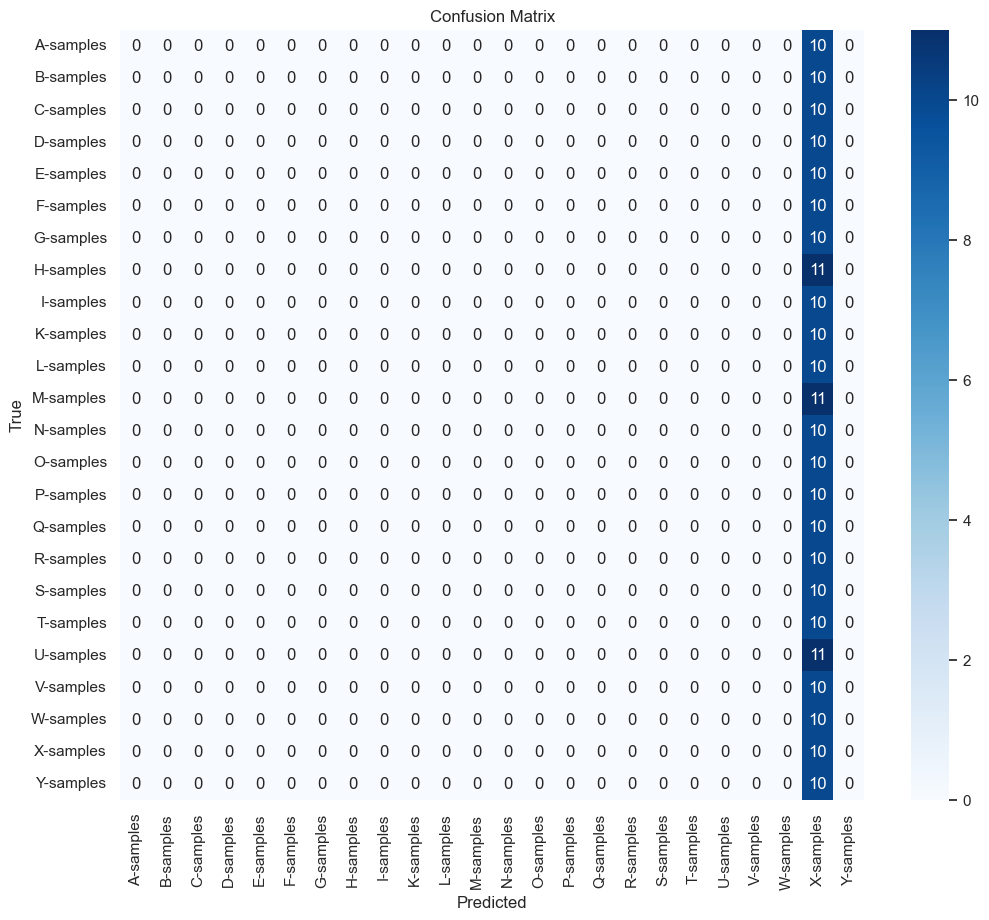


--- Classification Report ---
              precision    recall  f1-score   support

   A-samples       0.00      0.00      0.00        10
   B-samples       0.00      0.00      0.00        10
   C-samples       0.00      0.00      0.00        10
   D-samples       0.00      0.00      0.00        10
   E-samples       0.00      0.00      0.00        10
   F-samples       0.00      0.00      0.00        10
   G-samples       0.00      0.00      0.00        10
   H-samples       0.00      0.00      0.00        11
   I-samples       0.00      0.00      0.00        10
   K-samples       0.00      0.00      0.00        10
   L-samples       0.00      0.00      0.00        10
   M-samples       0.00      0.00      0.00        11
   N-samples       0.00      0.00      0.00        10
   O-samples       0.00      0.00      0.00        10
   P-samples       0.00      0.00      0.00        10
   Q-samples       0.00      0.00      0.00        10
   R-samples       0.00      0.00      0.00       

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [31]:
# --- Experiment 2: Baseline CNN + Data Augmentation ---
print("\n=== Running Experiment 2: Baseline CNN + Data Augmentation ===")

# 1. Create Generators
# Re-defining augmentor with rescale to ensure output is 0-1 like validation data
# combined_preprocessing returns 0-255, so we add rescale=1./255
train_datagen_aug = ImageDataGenerator(
    rotation_range=30, width_shift_range=0.2, height_shift_range=0.2,
    shear_range=0.2, zoom_range=0.3, horizontal_flip=True, fill_mode='nearest',
    preprocessing_function=combined_preprocessing,
    rescale=1./255 
)

train_gen_exp2 = train_datagen_aug.flow_from_dataframe(
    train_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=True
)

val_gen_exp2 = val_test_datagen.flow_from_dataframe(
    val_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

test_gen_exp2 = val_test_datagen.flow_from_dataframe(
    test_df, x_col='filepath', y_col='label',
    target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', shuffle=False
)

# 2. Build & Compile Model (Fresh Instance)
model_exp2 = build_baseline_cnn(INPUT_SHAPE, NUM_CLASSES)
model_exp2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 3. Train
history_exp2 = model_exp2.fit(
    train_gen_exp2,
    validation_data=val_gen_exp2,
    epochs=EPOCHS,
    callbacks=callbacks
)

# 4. Visualize Results
plot_training_history(history_exp2, title="Exp 2: Baseline + Augmentation")

# 5. Evaluate
print("\n--- Evaluation: Experiment 2 ---")
evaluate_model(model_exp2, test_gen_exp2)

# Store Results
experiment_results['Exp2_Baseline_Aug'] = {
    'accuracy': history_exp2.history['accuracy'][-1],
    'val_accuracy': history_exp2.history['val_accuracy'][-1],
    'loss': history_exp2.history['loss'][-1],
    'val_loss': history_exp2.history['val_loss'][-1]
}


=== Running Experiment 3: Transfer Learning (ResNet50) ===
Epoch 1/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 134s 2s/step - accuracy: 0.0392 - loss: 3.2848 - val_accuracy: 0.0412 - val_loss: 3.1786 - learning_rate: 0.0010
Epoch 2/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 129s 2s/step - accuracy: 0.0402 - loss: 3.1794 - val_accuracy: 0.0412 - val_loss: 3.1781 - learning_rate: 0.0010
Epoch 3/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - accuracy: 0.0407 - loss: 3.1784 - val_accuracy: 0.0412 - val_loss: 3.1781 - learning_rate: 0.0010
Epoch 4/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.0438 - loss: 3.1784 - val_accuracy: 0.0412 - val_loss: 3.1781 - learning_rate: 0.0010
Epoch 5/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.0409 - loss: 3.1783
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
61/61 ━━━━━━━━━━━━━━━━━━━━ 127s 2s/step - accuracy: 0.0438 - loss: 3.1784 - val_accuracy: 0.0412 - val_loss: 3.1781 - learning_rate: 0.0010
Epoch 6/50
61/61 ━━━━━━━━━━━━━━━━━━━━

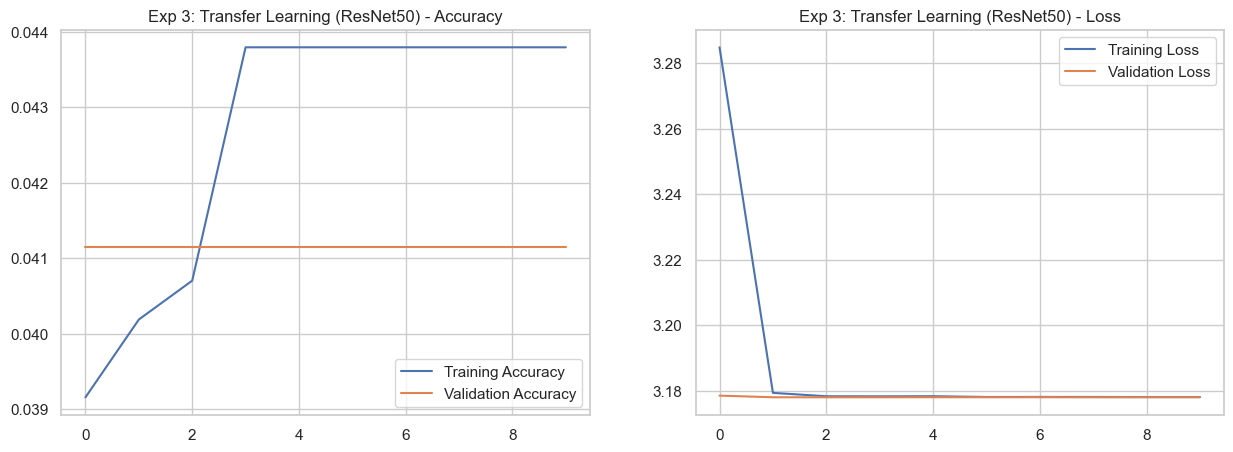


--- Evaluation: Experiment 3 ---
8/8 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step
Accuracy: 0.0412
Precision: 0.0017
Recall: 0.0412
F1-Score: 0.0033


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


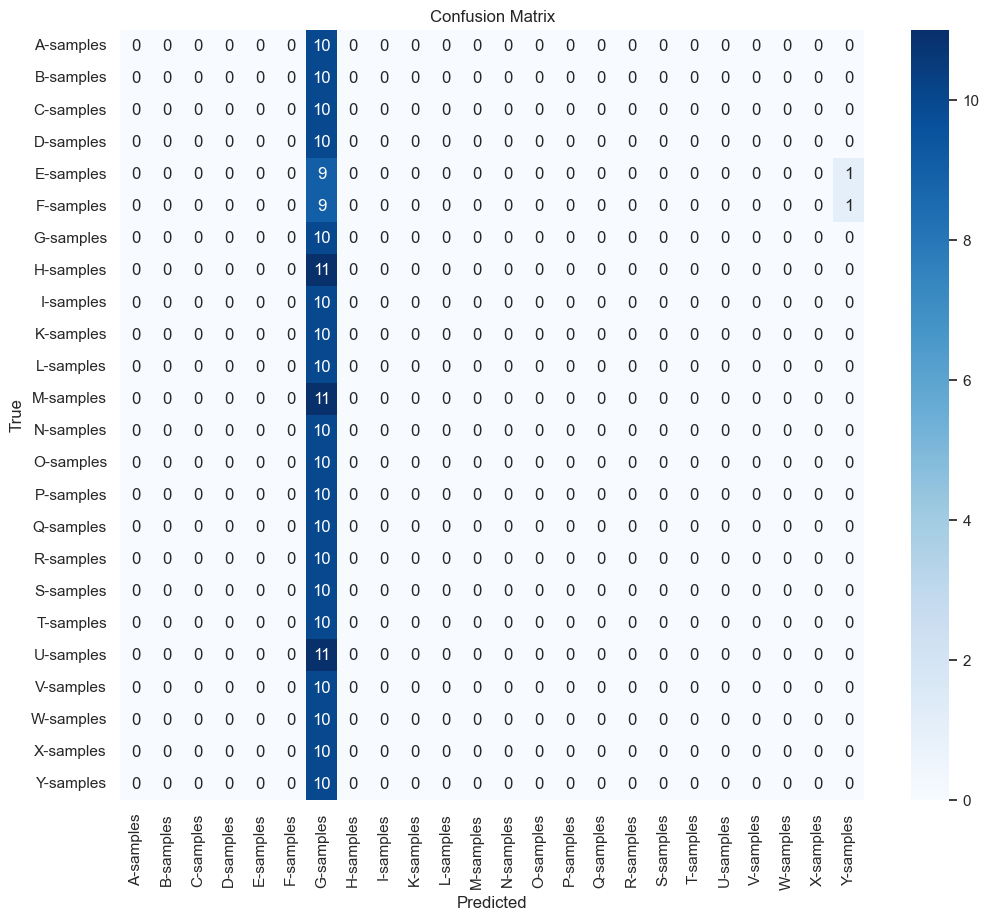


--- Classification Report ---
              precision    recall  f1-score   support

   A-samples       0.00      0.00      0.00        10
   B-samples       0.00      0.00      0.00        10
   C-samples       0.00      0.00      0.00        10
   D-samples       0.00      0.00      0.00        10
   E-samples       0.00      0.00      0.00        10
   F-samples       0.00      0.00      0.00        10
   G-samples       0.04      1.00      0.08        10
   H-samples       0.00      0.00      0.00        11
   I-samples       0.00      0.00      0.00        10
   K-samples       0.00      0.00      0.00        10
   L-samples       0.00      0.00      0.00        10
   M-samples       0.00      0.00      0.00        11
   N-samples       0.00      0.00      0.00        10
   O-samples       0.00      0.00      0.00        10
   P-samples       0.00      0.00      0.00        10
   Q-samples       0.00      0.00      0.00        10
   R-samples       0.00      0.00      0.00       

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [32]:
# --- Experiment 3: Transfer Learning (ResNet50) ---
print("\n=== Running Experiment 3: Transfer Learning (ResNet50) ===")

# Reuse generators from Exp 2 (Augmented for Training, Scaled for Val)
train_gen_exp3 = train_gen_exp2
val_gen_exp3 = val_gen_exp2
test_gen_exp3 = test_gen_exp2

# Rebuild Model to ensure fresh start
transfer_model_final = build_transfer_learning_model('ResNet50', INPUT_SHAPE, NUM_CLASSES)
transfer_model_final.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train
history_exp3 = transfer_model_final.fit(
    train_gen_exp3,
    validation_data=val_gen_exp3,
    epochs=EPOCHS,
    callbacks=callbacks
)

# Visualize Results
plot_training_history(history_exp3, title="Exp 3: Transfer Learning (ResNet50)")

# Evaluate
print("\n--- Evaluation: Experiment 3 ---")
evaluate_model(transfer_model_final, test_gen_exp3)

# Store Results
experiment_results['Exp3_Transfer_ResNet'] = {
    'accuracy': history_exp3.history['accuracy'][-1],
    'val_accuracy': history_exp3.history['val_accuracy'][-1],
    'loss': history_exp3.history['loss'][-1],
    'val_loss': history_exp3.history['val_loss'][-1]
}


=== Experiment 4: Model Comparison ===
Results Summary Table:
                      accuracy  val_accuracy      loss  val_loss
Exp1_Baseline_NoAug   0.046883      0.041152  3.178041  3.177962
Exp2_Baseline_Aug     0.043792      0.041152  3.178101  3.178069
Exp3_Transfer_ResNet  0.043792      0.041152  3.178143  3.178072


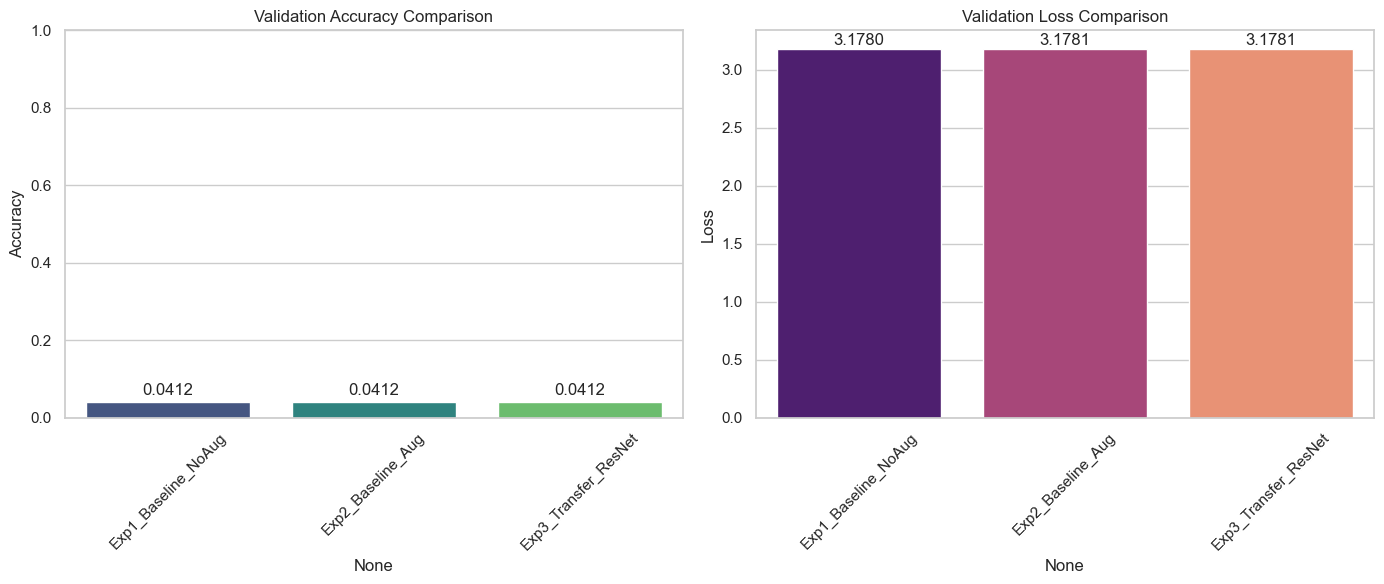

In [33]:
# --- Experiment 4: Comparison of Architectures ---
print("\n=== Experiment 4: Model Comparison ===")
import pandas as pd

# Create DataFrame from results
results_df = pd.DataFrame(experiment_results).T
print("Results Summary Table:")
print(results_df)

# Plot Comparison
plt.figure(figsize=(14, 6))

# Accuracy Comparison
plt.subplot(1, 2, 1)
sns.barplot(x=results_df.index, y=results_df['val_accuracy'], palette='viridis', hue=results_df.index, legend=False)
plt.title('Validation Accuracy Comparison')
plt.ylabel('Accuracy')
plt.xticks(rotation=45)
plt.ylim(0, 1.0) # Accuracy is between 0 and 1
for i, v in enumerate(results_df['val_accuracy']):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center', va='bottom')

# Loss Comparison
plt.subplot(1, 2, 2)
sns.barplot(x=results_df.index, y=results_df['val_loss'], palette='magma', hue=results_df.index, legend=False)
plt.title('Validation Loss Comparison')
plt.ylabel('Loss')
plt.xticks(rotation=45)
for i, v in enumerate(results_df['val_loss']):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center', va='bottom')

plt.tight_layout()
plt.show()